# 04 — RFM Segmentation, Cohort Analysis & Advanced KPIs
### E-Commerce Customer Analytics Dashboard

This notebook covers the most advanced analytical work in the project:

1. **RFM Analysis** (Recency, Frequency, Monetary) → customer segments
   (Champions, Loyal, At Risk, Lost, etc.)
2. **Cohort Analysis** → monthly acquisition cohorts and retention over time
3. **Advanced KPIs**: Revenue Growth %, Profit Margin %, Customer Retention
   Rate, Average Basket Size, Repeat Purchase Rate

Outputs: `customer_rfm.csv`, `cohort_retention_table.csv`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

IMG_DIR = '../images'

df = pd.read_csv('../data/ecommerce_features.csv', parse_dates=['Order_Date'])
print(df.shape)
df.head(3)


(12118, 31)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,...,Year_Quarter,Year_Month,Day_of_Week,Profit_Margin,Gross_Sales,Discount_Amount,Total_Orders,Customer_Lifetime_Value,Average_Order_Value,Is_Repeat_Customer
0,ORD010477,2024-09-08,CUST01027,Aarav Bava,Female,34,Nagpur,Maharashtra,West,Beauty & Personal Care,...,2024-Q3,2024-09,Sunday,47.37,1366.44,68.32,4,11014.37,2753.59,True
1,ORD008646,2023-10-05,CUST00581,Bhavya Borah,Male,37,Ranchi,Jharkhand,East,Sports & Fitness,...,2023-Q4,2023-10,Thursday,40.00,10380.80,0.00,20,159881.56,7994.08,True
2,ORD011576,2023-08-08,CUST00653,Sanya Wable,Female,31,Bhubaneswar,Odisha,East,Books,...,2023-Q3,2023-08,Tuesday,40.00,722.57,0.00,48,358731.11,7473.56,True


## 1. RFM Analysis

- **Recency** — days since the customer's most recent order (lower = more recent = better)
- **Frequency** — number of distinct orders placed
- **Monetary** — total revenue (Sales) generated by the customer

We score each dimension 1–5 using quintiles (5 = best) and combine into an
`RFM_Score`, then map combinations to human-readable segments.


In [2]:
snapshot_date = df['Order_Date'].max() + pd.Timedelta(days=1)
print('Snapshot date (analysis "today"):', snapshot_date.date())

rfm = df.groupby('Customer_ID').agg(
    Recency=('Order_Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Order_ID', 'nunique'),
    Monetary=('Sales', 'sum')
).reset_index()

rfm['Monetary'] = rfm['Monetary'].round(2)
rfm.head()


Snapshot date (analysis "today"): 2024-12-29


,Customer_ID,Recency,Frequency,Monetary
0,CUST00001,1059,1,788.16
1,CUST00002,18,12,66318.03
2,CUST00003,85,36,132723.38
3,CUST00004,49,5,9115.02
4,CUST00005,45,12,71086.12


In [3]:
# Quintile scoring. Recency: lower days = better => score reversed (5 = most recent)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Total'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

rfm.head()


,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,CUST00001,1059,1,788.16,1,1,1,111,3
1,CUST00002,18,12,66318.03,5,4,3,543,12
2,CUST00003,85,36,132723.38,3,5,4,354,12
3,CUST00004,49,5,9115.02,4,3,2,432,9
4,CUST00005,45,12,71086.12,4,4,3,443,11


### Segment Mapping

A standard, widely-used RFM segmentation scheme (used across retail/e-commerce
analytics) based on the R and F scores:


In [4]:
def rfm_segment(row):
    r, f = row['R_Score'], row['F_Score']
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r == 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 4:
        return 'At Risk'
    elif r <= 2 and f >= 2:
        return 'Needs Attention'
    elif r <= 2 and f <= 1:
        return 'Lost'
    else:
        return 'Others'

rfm['Segment'] = rfm.apply(rfm_segment, axis=1)

segment_summary = rfm.groupby('Segment').agg(
    Customers=('Customer_ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).sort_values('Total_Revenue', ascending=False).round(1)

segment_summary


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Segment,,,,,
Champions,312,22.5,25.9,322278.3,100550825.2
Loyal Customers,236,57.5,8.3,101664.7,23992864.6
Needs Attention,226,296.0,3.9,45225.6,10220989.8
At Risk,46,194.2,10.4,121460.5,5587184.8
Lost,183,522.7,1.3,15160.5,2774368.7
New Customers,67,30.1,2.7,32633.6,2186448.4
Potential Loyalists,67,72.2,2.6,22707.9,1521426.2


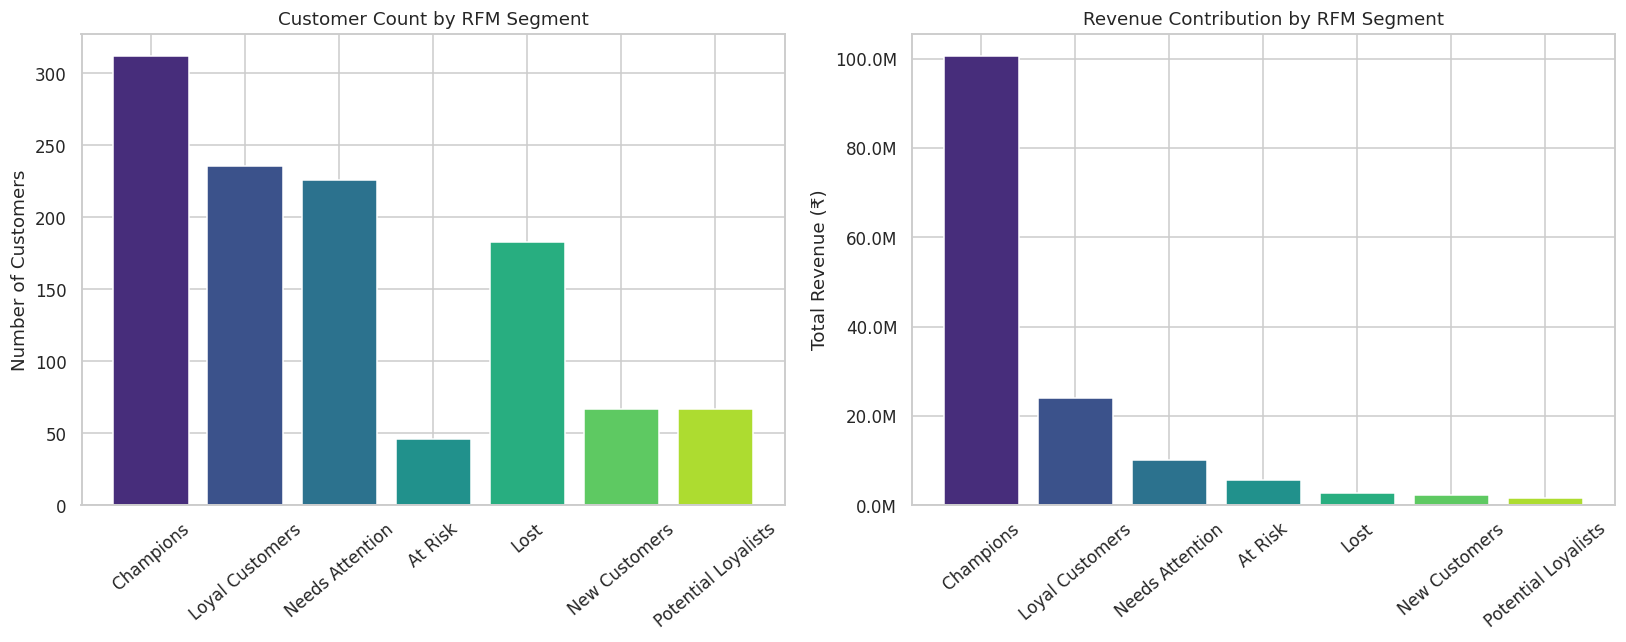

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

order = segment_summary.index
colors = sns.color_palette('viridis', len(order))

axes[0].bar(order, segment_summary['Customers'], color=colors)
axes[0].set_title('Customer Count by RFM Segment')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=40)

axes[1].bar(order, segment_summary['Total_Revenue'], color=colors)
axes[1].set_title('Revenue Contribution by RFM Segment')
axes[1].set_ylabel('Total Revenue (₹)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
axes[1].tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.savefig(f'{IMG_DIR}/09_rfm_segmentation.png', bbox_inches='tight')
plt.show()


In [6]:
rfm.to_csv('../data/customer_rfm.csv', index=False)
print('Saved ../data/customer_rfm.csv ->', rfm.shape)


Saved ../data/customer_rfm.csv -> (1137, 10)


## 2. Cohort Analysis

Each customer is assigned a **cohort** = the month of their first purchase.
We then track what % of each cohort is still active (placing orders) in each
subsequent month — the classic retention heatmap.


In [7]:
df['Order_Month'] = df['Order_Date'].dt.to_period('M')

first_purchase = df.groupby('Customer_ID')['Order_Month'].min().reset_index()
first_purchase.columns = ['Customer_ID', 'Cohort_Month']

df_cohort = df.merge(first_purchase, on='Customer_ID')

# Cohort index = number of months since first purchase
df_cohort['Cohort_Index'] = (
    (df_cohort['Order_Month'].dt.year - df_cohort['Cohort_Month'].dt.year) * 12 +
    (df_cohort['Order_Month'].dt.month - df_cohort['Cohort_Month'].dt.month)
)

cohort_data = df_cohort.groupby(['Cohort_Month', 'Cohort_Index'])['Customer_ID'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='Cohort_Month', columns='Cohort_Index', values='Customer_ID')

cohort_sizes = cohort_pivot.iloc[:, 0]
retention_table = cohort_pivot.divide(cohort_sizes, axis=0).round(3) * 100

retention_table.iloc[:12, :12]  # preview first 12 cohorts x 12 months


Cohort_Index,0,1,2,3,4,5,6,7,8,9,10,11
Cohort_Month,,,,,,,,,,,,
2022-01,100.0,25.9,27.1,30.1,34.9,33.7,31.9,36.1,33.7,45.2,39.2,34.9
2022-02,100.0,25.3,15.8,17.9,18.9,14.7,15.8,26.3,31.6,24.2,25.3,22.1
2022-03,100.0,14.3,18.4,24.5,17.3,17.3,21.4,34.7,32.7,27.6,25.5,22.4
2022-04,100.0,11.6,17.4,18.6,16.3,16.3,20.9,29.1,14.0,20.9,12.8,14.0
2022-05,100.0,8.1,13.5,16.2,10.8,23.0,21.6,20.3,24.3,16.2,18.9,24.3
2022-06,100.0,19.1,17.0,12.8,27.7,17.0,19.1,14.9,27.7,17.0,17.0,25.5
2022-07,100.0,11.5,11.5,13.5,15.4,9.6,19.2,7.7,13.5,25.0,13.5,13.5
2022-08,100.0,14.0,20.9,30.2,11.6,20.9,23.3,20.9,18.6,9.3,11.6,9.3
2022-09,100.0,11.4,27.3,6.8,15.9,20.5,15.9,13.6,4.5,11.4,18.2,18.2


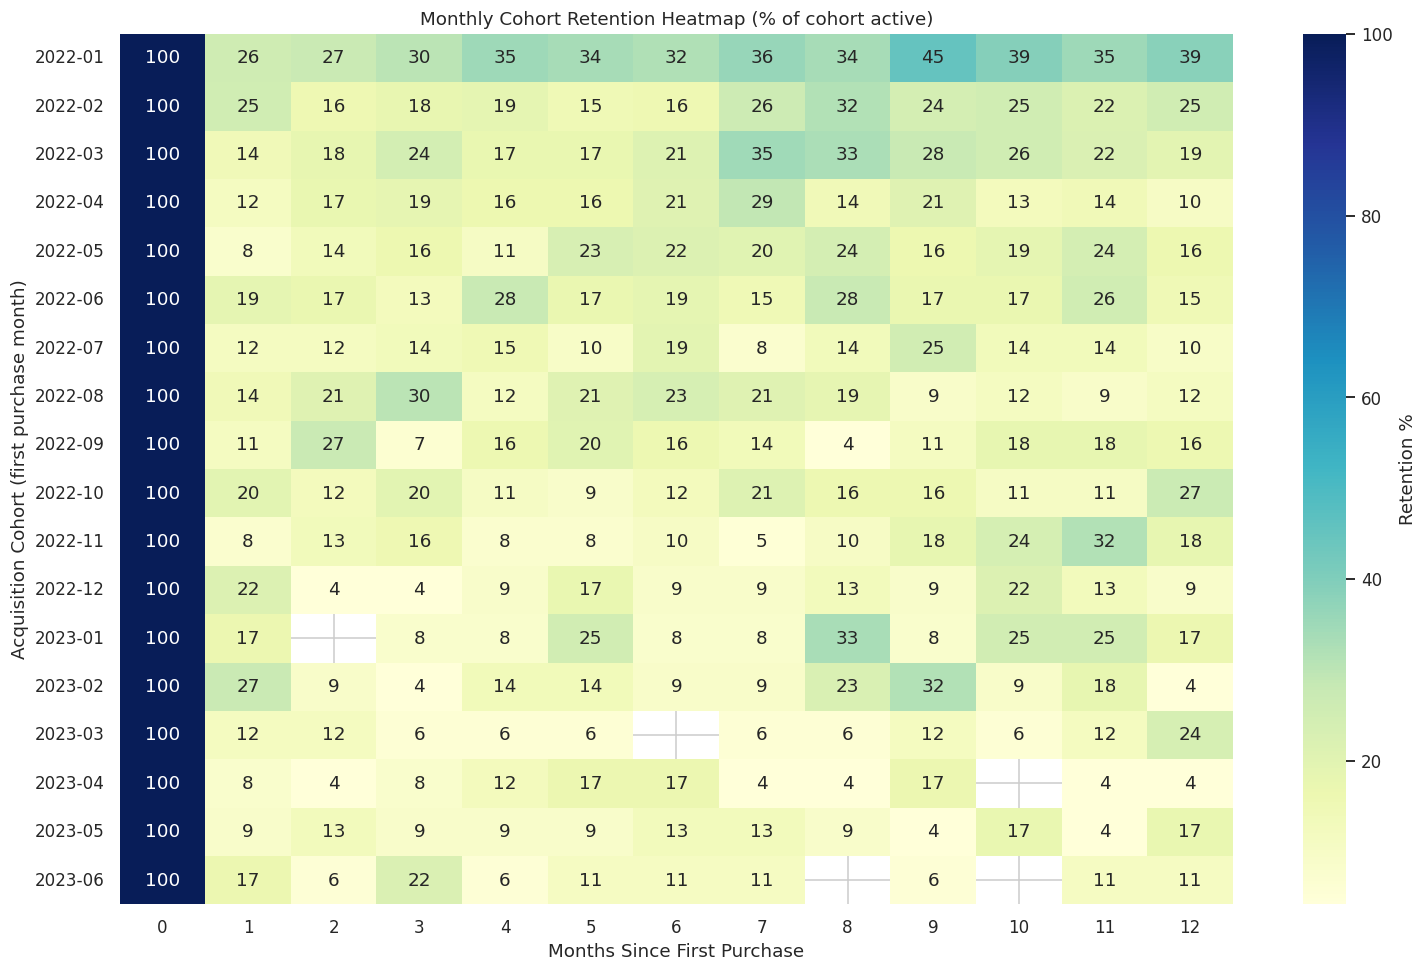

In [8]:
fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(retention_table.iloc[:18, :13], annot=True, fmt='.0f', cmap='YlGnBu',
            cbar_kws={'label': 'Retention %'}, ax=ax)
ax.set_title('Monthly Cohort Retention Heatmap (% of cohort active)')
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Acquisition Cohort (first purchase month)')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/10_cohort_retention_heatmap.png', bbox_inches='tight')
plt.show()


In [9]:
retention_table.to_csv('../data/cohort_retention_table.csv')
print('Saved ../data/cohort_retention_table.csv ->', retention_table.shape)


Saved ../data/cohort_retention_table.csv -> (36, 36)


**Reading the heatmap:** Month 0 is always 100% (the cohort's first purchase
month, by definition). Each subsequent column shows the percentage of that
cohort who placed *another* order N months later. A naturally declining
pattern across columns is expected and typical for retail; what matters for
the business is whether later cohorts retain *better* than earlier ones
(an indicator that retention initiatives are working).


## 3. Advanced KPIs

In [10]:
# --- Revenue Growth % (Year-over-Year) ---
yearly_revenue = df.groupby('Year')['Sales'].sum()
yoy_growth = yearly_revenue.pct_change() * 100

print("Yearly Revenue:")
print(yearly_revenue.round(2))
print()
print("YoY Revenue Growth %:")
print(yoy_growth.round(2))


Yearly Revenue:
Year
2022    33729985.30
2023    53981051.33
2024    59123071.05
Name: Sales, dtype: float64

YoY Revenue Growth %:
Year
2022      NaN
2023    60.04
2024     9.53
Name: Sales, dtype: float64


In [11]:
# --- Profit Margin % (overall) ---
overall_profit_margin = (df['Profit'].sum() / df['Sales'].sum()) * 100
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")


Overall Profit Margin: 21.02%


In [12]:
# --- Customer Retention Rate ---
# Defined here as: % of customers who purchased in period N who also purchased in period N+1
# Using quarters as the period for a stable sample size.
df['Year_Quarter_Period'] = df['Order_Date'].dt.to_period('Q')
quarters = sorted(df['Year_Quarter_Period'].unique())

retention_rates = []
for i in range(len(quarters) - 1):
    q_curr, q_next = quarters[i], quarters[i + 1]
    cust_curr = set(df.loc[df['Year_Quarter_Period'] == q_curr, 'Customer_ID'])
    cust_next = set(df.loc[df['Year_Quarter_Period'] == q_next, 'Customer_ID'])
    retained = len(cust_curr & cust_next)
    rate = retained / len(cust_curr) * 100 if cust_curr else 0
    retention_rates.append({'Quarter': str(q_curr), 'Next_Quarter': str(q_next),
                             'Customers_in_Q': len(cust_curr), 'Retained_in_Next_Q': retained,
                             'Retention_Rate_%': round(rate, 2)})

retention_df = pd.DataFrame(retention_rates)
retention_df


,Quarter,Next_Quarter,Customers_in_Q,Retained_in_Next_Q,Retention_Rate_%
0,2022Q1,2022Q2,359,176,49.03
1,2022Q2,2022Q3,383,180,47.00
2,2022Q3,2022Q4,385,220,57.14
3,2022Q4,2023Q1,476,253,53.15
4,2023Q1,2023Q2,429,244,56.88
5,2023Q2,2023Q3,452,265,58.63
6,2023Q3,2023Q4,479,329,68.68
7,2023Q4,2024Q1,611,338,55.32
8,2024Q1,2024Q2,490,272,55.51
9,2024Q2,2024Q3,464,267,57.54


In [13]:
avg_quarterly_retention = retention_df['Retention_Rate_%'].mean()
print(f"Average Quarter-over-Quarter Customer Retention Rate: {avg_quarterly_retention:.2f}%")


Average Quarter-over-Quarter Customer Retention Rate: 57.31%


In [14]:
# --- Average Basket Size (avg. quantity of items per order) ---
basket_size = df.groupby('Order_ID')['Quantity'].sum()
avg_basket_size = basket_size.mean()
print(f"Average Basket Size: {avg_basket_size:.2f} items per order")


Average Basket Size: 1.93 items per order


In [15]:
# --- Repeat Purchase Rate ---
orders_per_customer = df.groupby('Customer_ID')['Order_ID'].nunique()
repeat_customers = (orders_per_customer > 1).sum()
total_customers = orders_per_customer.shape[0]
repeat_purchase_rate = repeat_customers / total_customers * 100

print(f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}% "
      f"({repeat_customers:,} of {total_customers:,} customers ordered more than once)")


Repeat Purchase Rate: 86.19% (980 of 1,137 customers ordered more than once)


In [16]:
# --- Consolidated KPI summary table ---
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Revenue', 'Total Profit', 'Overall Profit Margin %',
        'Total Orders', 'Total Customers', 'Average Order Value',
        'Average Basket Size (items/order)', 'Repeat Purchase Rate %',
        'Avg. Quarter-over-Quarter Retention Rate %'
    ],
    'Value': [
        f"₹{df['Sales'].sum():,.2f}",
        f"₹{df['Profit'].sum():,.2f}",
        f"{overall_profit_margin:.2f}%",
        f"{df['Order_ID'].nunique():,}",
        f"{df['Customer_ID'].nunique():,}",
        f"₹{df['Sales'].sum() / df['Order_ID'].nunique():,.2f}",
        f"{avg_basket_size:.2f}",
        f"{repeat_purchase_rate:.2f}%",
        f"{avg_quarterly_retention:.2f}%",
    ]
})
kpi_summary.to_csv('../reports/kpi_summary.csv', index=False)
kpi_summary


,KPI,Value
0,Total Revenue,"₹146,834,107.68"
1,Total Profit,"₹30,863,842.06"
2,Overall Profit Margin %,21.02%
3,Total Orders,"11,978"
4,Total Customers,"1,137"
5,Average Order Value,"₹12,258.65"
6,Average Basket Size (items/order),1.93
7,Repeat Purchase Rate %,86.19%
8,Avg. Quarter-over-Quarter Retention Rate %,57.31%


---
This completes the Python analysis layer. The next step is the SQL query
set (`/sql`) — written against the same schema — and the Power BI dashboard
design (`/dashboard`), both of which reuse the metrics defined here.
